In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold

In [24]:
df = pd.read_csv('course_lead_scoring_2026.csv')

In [25]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [26]:
df.dtypes

lead_source                  object
industry                     object
employment_status            object
location                     object
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [27]:
categorical = list(df.dtypes[df.dtypes == 'object'].index)
numerical = list(df.dtypes[df.dtypes != 'object'].index)

In [28]:
if 'converted' in numerical:
    numerical.remove('converted')
if 'converted' in categorical:
    categorical.remove('converted')

In [29]:
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

In [30]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [31]:
df_train.shape

(3000, 9)

In [32]:
df_val.shape

(1000, 9)

In [33]:
df_test.shape

(1000, 9)

In [34]:
y_train = df_train['converted'].values
y_val = df_val['converted'].values
y_test = df_test['converted'].values

In [35]:
del df_train['converted']
del df_val['converted']
del df_test['converted']

In [36]:
# roc auc feature importance

num_features = ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']

for col in num_features:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    print(f'{col}: {auc:.4f}')

lead_score: 0.7882
number_of_courses_viewed: 0.7230
interaction_count: 0.7649
annual_income: 0.6082


In [ ]:
# model auc

dv = DictVectorizer(sparse=False)

train_dict = df_train.to_dict(orient='records')
x_train = dv.fit_transform(train_dict)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=100)
model.fit(x_train, y_train)

val_dict = df_val.to_dict(orient='records')
x_val = dv.transform(val_dict)

y_pred = model.predict_proba(x_val)[:, 1]

auc = roc_auc_score(y_val, y_pred)
print(f'AUC on validation: {auc: .3f}')

AUC on validation:  0.732


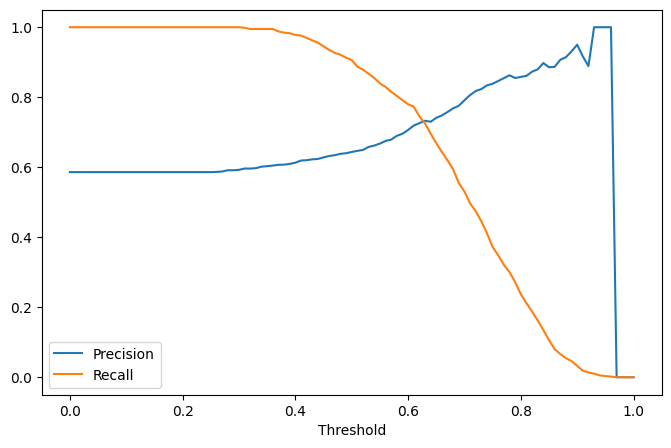

Intersection threshold: 0.63


In [ ]:
# precision and recall

thresholds = np.linspace(0, 1, 101)
precisions = []
recalls = []

for t in thresholds:
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)
    
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    p = tp / (tp + fp) if (tp + fp) > 0 else 0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    precisions.append(p)
    recalls.append(r)

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions, label='Precision')
plt.plot(thresholds, recalls, label='Recall')
plt.xlabel('Threshold')
plt.legend()
plt.show()

min_diff = float('inf')
best_t = 0
for i, t in enumerate(thresholds):
    if precisions[i] > 0 and recalls[i] > 0:
        diff = abs(precisions[i] - recalls[i])
        if diff < min_diff:
            min_diff = diff
            best_t = t

print(f'Intersection threshold: {best_t}')

In [39]:
# f1 score

f1_scores = []
for p, r in zip(precisions, recalls):
    if p + r == 0:
        f1_scores.append(0)
    else:
        f1 = 2 * p * r / (p + r)
        f1_scores.append(f1)

max_f1_idx = np.argmax(f1_scores)
print(f'Threshold for max F1: {thresholds[max_f1_idx]}')

Threshold for max F1: 0.41000000000000003


In [40]:
# 5-fold CV standard deviation

def train(df_train, y_train, C=1.0):
    dicts = df_train.to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    return dv, model

def predict(df, dv, model):
    dicts = df.to_dict(orient='records')
    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]
    return y_pred

kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train_cv = df_full_train.iloc[train_idx]
    df_val_cv = df_full_train.iloc[val_idx]

    y_train_cv = df_train_cv['converted'].values
    y_val_cv = df_val_cv['converted'].values

    df_train_cv = df_train_cv.drop('converted', axis=1)
    df_val_cv = df_val_cv.drop('converted', axis=1)

    dv_cv, model_cv = train(df_train_cv, y_train_cv, C=1.0)
    y_pred_cv = predict(df_val_cv, dv_cv, model_cv)

    auc_cv = roc_auc_score(y_val_cv, y_pred_cv)
    scores.append(auc_cv)

print(f'Standard Deviation of AUC scores: {np.std(scores):.3f}')

Standard Deviation of AUC scores: 0.007


In [41]:
# hyperparameter tuning

for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train_cv = df_full_train.iloc[train_idx]
        df_val_cv = df_full_train.iloc[val_idx]

        y_train_cv = df_train_cv['converted'].values
        y_val_cv = df_val_cv['converted'].values

        df_train_cv = df_train_cv.drop('converted', axis=1)
        df_val_cv = df_val_cv.drop('converted', axis=1)

        dv_cv, model_cv = train(df_train_cv, y_train_cv, C=C)
        y_pred_cv = predict(df_val_cv, dv_cv, model_cv)

        auc_cv = roc_auc_score(y_val_cv, y_pred_cv)
        scores.append(auc_cv)

    print(f'C = {C:<8} | Mean AUC: {np.mean(scores):.3f} +- {np.std(scores):.3f}')

C = 1e-06    | Mean AUC: 0.617 +- 0.019
C = 0.001    | Mean AUC: 0.749 +- 0.010
C = 1        | Mean AUC: 0.732 +- 0.007
